# NGC 253: first-pass H II region and SNR/shock catalogue

This notebook keeps the original global-noise detection image and treats H II regions and SNR/shock candidates in one extended-nebula branch.

The segmentation is now split into three simple steps:

1. **Astrodendro finds reliable peaks only.** Each dendrogram leaf contributes one marker at its peak.
2. **Watershed assigns surrounding emission to those markers.** The watershed operates on the detection image, not on a smoothed binary mask.
3. **The boundary of each region is reduced to the isophote containing 90% of its positive, locally background-subtracted detection flux.**

No planetary-nebula mask or PN classification is used here. No segmented region is automatically rejected; quality quantities are retained only for inspection.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

from astropy.io import fits
from astropy.wcs import WCS
from astrodendro import Dendrogram

from skimage.measure import regionprops_table
from skimage.segmentation import watershed, find_boundaries, relabel_sequential

from tqdm.notebook import tqdm

## Configuration

In [35]:
# Input and output paths
DATA_FITS = Path("/Users/golta/Desktop/Uni/Thesis/Model Selection/Classic_V2.0/ADP.2025-07-06T07_52_11.876.fits")
OUTPUT_DIR = Path("./results")

# Image properties
PIX_SCALE = 0.2                 # arcsec / pixel
PSF_FWHM_ARCSEC = 0.85

# Detection image: global error level for each line
NOISE_METHOD = "median"
DETECTION_SNR_MIN = 0.0

# Watershed and final boundary
SUPPORT_THRESHOLD = 10.0         # combined global-noise S/N-like detection value
WATERSHED_SMOOTH_SIGMA = 2.0    # smooth the intensity image, not the binary mask
BOUNDARY_FLUX_FRACTION = 0.90
BOUNDARY_ANNULUS_INNER_PIX = 2
BOUNDARY_ANNULUS_OUTER_PIX = 8

# Local background used for integrated line fluxes
ANNULUS_INNER_FACTOR = 0.8
ANNULUS_OUTER_FACTOR = 1.4
MIN_ANNULUS_PIX = 30

# First-pass line measurement and classification thresholds
LINE_SN_MIN = 3.0
HA_CONTRAST_MIN = 3.0
SII_HA_DIG_LIKE = 0.35
SII_HA_SHOCK_LIKE = 0.40
OI_HA_SHOCK_LIKE = 0.05

## Basic utilities and detection image

In [3]:
def percentile_norm(img, pmin=1, pmax=99):
    x = np.array(img, dtype=float, copy=True)
    x[~np.isfinite(x)] = np.nan

    lo, hi = np.nanpercentile(x, [pmin, pmax])
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        return np.zeros_like(x)

    return np.clip((x - lo) / (hi - lo), 0, 1)


def clean_map(x):
    y = np.array(x, dtype=float, copy=True)
    y[~np.isfinite(y)] = 0.0
    y[y < 0] = 0.0
    return y


def global_noise(err, method="median"):
    err = np.asarray(err, dtype=float)
    vals = err[np.isfinite(err) & (err > 0)]

    if vals.size == 0:
        raise ValueError("The error map contains no finite positive values.")

    if method == "median":
        return np.nanmedian(vals)
    if method == "rms":
        return np.sqrt(np.nanmedian(vals**2))
    if method == "percentile":
        return np.nanpercentile(vals, 60)

    return np.nanmean(vals)


def det_map(ha, ha_err, oiii, oiii_err, sii, sii_err,
            snr_min=0.0, noise_method="median"):
    """Combine Halpha, [O III], and [S II] using one global noise value per line."""
    fluxes = [ha, oiii, sii]
    errors = [ha_err, oiii_err, sii_err]
    noises = [global_noise(err, method=noise_method) for err in errors]

    detection_sq = np.zeros_like(ha, dtype=float)

    for flux, noise in zip(fluxes, noises):
        snr = np.asarray(flux, dtype=float) / noise
        snr[~np.isfinite(snr)] = 0.0
        snr = np.clip(snr, 0, None)

        if snr_min > 0:
            snr[snr < snr_min] = 0.0

        detection_sq += snr**2

    return np.sqrt(detection_sq)

## Marker watershed and 90% flux boundaries

In [4]:
def count_regions(labels):
    labels = np.asarray(labels)
    return len(np.unique(labels[labels > 0]))


def expand_slice(slc, image_shape, pad=0):
    yslc, xslc = slc
    ny, nx = image_shape[:2]

    y0 = max(yslc.start - pad, 0)
    y1 = min(yslc.stop + pad, ny)
    x0 = max(xslc.start - pad, 0)
    x1 = min(xslc.stop + pad, nx)

    return np.s_[y0:y1, x0:x1]


def dendrogram_markers(detection, min_value, min_delta, min_npix):
    """Use one peak pixel from each astrodendro leaf as a watershed marker."""
    dendro = Dendrogram.compute(
        detection,
        min_value=min_value,
        min_delta=min_delta,
        min_npix=min_npix)

    markers = np.zeros(detection.shape, dtype=np.int32)

    for marker_id, leaf in enumerate(dendro.leaves, start=1):
        peak_index, _ = leaf.get_peak()
        markers[tuple(peak_index)] = marker_id

    return markers, dendro


def watershed_from_markers(detection, markers,
                           support_threshold=5.0,
                           smooth_sigma=1.0):
    """Assign pixels above the support threshold to reliable dendrogram markers."""
    data = clean_map(detection)
    surface = ndi.gaussian_filter(data, smooth_sigma) if smooth_sigma > 0 else data
    support_mask = data >= support_threshold

    labels = watershed(
        -surface,
        markers=markers,
        mask=support_mask)

    return labels.astype(np.int32), support_mask


def refine_boundaries(labels, markers, detection,
                      flux_fraction=0.90,
                      annulus_inner_pix=2,
                      annulus_outer_pix=8):
    """Keep the marker-connected isophote containing the requested positive flux fraction."""
    labels = np.asarray(labels, dtype=np.int32)
    detection = clean_map(detection)
    refined = np.zeros_like(labels, dtype=np.int32)

    for region_id, base_slc in enumerate(ndi.find_objects(labels), start=1):
        if base_slc is None:
            continue

        slc = expand_slice(base_slc, labels.shape, pad=annulus_outer_pix + 2)
        labels_crop = labels[slc]
        region_crop = labels_crop == region_id

        # Local background immediately outside the watershed region.
        distance = ndi.distance_transform_edt(~region_crop)
        annulus = (
            (distance > annulus_inner_pix)
            & (distance <= annulus_outer_pix)
            & (labels_crop == 0)
        )

        annulus_values = detection[slc][annulus]
        annulus_values = annulus_values[np.isfinite(annulus_values)]
        background = np.nanmedian(annulus_values) if annulus_values.size else 0.0

        positive = np.clip(detection[slc] - background, 0, None)
        region_values = positive[region_crop]
        total_flux = np.sum(region_values)

        if total_flux <= 0:
            keep = region_crop
        else:
            sorted_values = np.sort(region_values)[::-1]
            cumulative = np.cumsum(sorted_values)
            index = np.searchsorted(cumulative, flux_fraction * total_flux)
            index = min(index, sorted_values.size - 1)
            isophote = sorted_values[index]
            candidate = region_crop & (positive >= isophote)

            # Keep the connected part containing the original dendrogram marker.
            components, _ = ndi.label(candidate)
            marker_crop = markers[slc] == region_id
            marker_components = np.unique(components[marker_crop])
            marker_components = marker_components[marker_components > 0]

            if marker_components.size:
                keep = components == marker_components[0]
            else:
                component_sizes = np.bincount(components.ravel())
                component_sizes[0] = 0
                keep = components == np.argmax(component_sizes)

            keep = ndi.binary_fill_holes(keep)

        refined_view = refined[slc]
        refined_view[keep] = region_id

    refined, _, _ = relabel_sequential(refined)
    return refined.astype(np.int32)


def run_segmentation(detection, min_value, min_delta, min_npix):
    markers, dendro = dendrogram_markers(
        detection,
        min_value=min_value,
        min_delta=min_delta,
        min_npix=min_npix,
    )

    watershed_labels, support_mask = watershed_from_markers(
        detection,
        markers,
        support_threshold=SUPPORT_THRESHOLD,
        smooth_sigma=WATERSHED_SMOOTH_SIGMA,
    )

    final_labels = refine_boundaries(
        watershed_labels,
        markers,
        detection,
        flux_fraction=BOUNDARY_FLUX_FRACTION,
        annulus_inner_pix=BOUNDARY_ANNULUS_INNER_PIX,
        annulus_outer_pix=BOUNDARY_ANNULUS_OUTER_PIX,
    )

    return {
        "dendrogram": dendro,
        "markers": markers,
        "support_mask": support_mask,
        "watershed_labels": watershed_labels,
        "labels_data": final_labels,
        "n_markers": count_regions(markers),
        "n_watershed_regions": count_regions(watershed_labels),
        "n_final_regions": count_regions(final_labels),
    }

In [5]:
def plot_segmentation_result(run_name, result, detection):
    det_show = percentile_norm(detection)
    marker_y, marker_x = np.where(result["markers"] > 0)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(det_show, origin="lower")
    axes[0].scatter(marker_x, marker_y, s=8, facecolors="none", edgecolors="red")
    axes[0].set_title(f"{run_name}: {result['n_markers']} dendrogram markers")

    axes[1].imshow(det_show, origin="lower")
    boundaries = find_boundaries(result["watershed_labels"], mode="outer")
    axes[1].contour(boundaries.astype(float), levels=[0.5], colors="red", linewidths=0.5)
    axes[1].set_title(f"Watershed: {result['n_watershed_regions']} regions")

    axes[2].imshow(det_show, origin="lower")
    boundaries = find_boundaries(result["labels_data"], mode="outer")
    axes[2].contour(boundaries.astype(float), levels=[0.5], colors="red", linewidths=0.5)
    axes[2].set_title(
        f"{BOUNDARY_FLUX_FRACTION:.0%} flux boundaries: "
        f"{result['n_final_regions']} regions"
    )

    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])

    plt.tight_layout()
    plt.show()

## Region measurements and local background subtraction

In [6]:
def make_region_catalog(labels_data, detection,
                        ha, ha_err, oiii, oiii_err, sii, sii_err,
                        wcs, pix_scale):
    labels = np.asarray(labels_data, dtype=np.int32)
    max_label = int(labels.max())

    if max_label == 0:
        return pd.DataFrame()

    props = pd.DataFrame(regionprops_table(
        labels,
        properties=(
            "label", "centroid", "bbox",
            "axis_major_length", "axis_minor_length", "eccentricity"
        ),
    ))

    region_ids = props["label"].to_numpy(dtype=np.int32)
    y = props["centroid-0"].to_numpy(float)
    x = props["centroid-1"].to_numpy(float)
    ra, dec = wcs.wcs_pix2world(x, y, 0)

    flat_labels = labels.ravel()
    minlength = max_label + 1
    npix_all = np.bincount(flat_labels, minlength=minlength)

    def sum_by_label(image):
        image = np.where(np.isfinite(image), image, 0.0)
        return np.bincount(flat_labels, weights=image.ravel(), minlength=minlength)

    def error_by_label(error):
        error2 = np.where(np.isfinite(error) & (error > 0), error**2, 0.0)
        return np.sqrt(np.bincount(flat_labels, weights=error2.ravel(), minlength=minlength))

    fluxes = {
        "ha": sum_by_label(ha),
        "oiii": sum_by_label(oiii),
        "sii": sum_by_label(sii),
    }
    errors = {
        "ha": error_by_label(ha_err),
        "oiii": error_by_label(oiii_err),
        "sii": error_by_label(sii_err),
    }

    det_peak = ndi.maximum(detection, labels, index=region_ids)
    det_median = np.full(region_ids.size, np.nan)

    for i, (region_id, slc) in enumerate(zip(region_ids, ndi.find_objects(labels))):
        if slc is None:
            continue
        values = detection[slc][labels[slc] == region_id]
        det_median[i] = np.nanmedian(values)

    npix = npix_all[region_ids].astype(int)
    r_eq_pix = np.sqrt(npix / np.pi)
    major = props["axis_major_length"].to_numpy(float)
    minor = props["axis_minor_length"].to_numpy(float)
    elongation = np.divide(major, minor, out=np.full_like(major, np.nan), where=minor > 0)

    min_row = props["bbox-0"].to_numpy(int)
    min_col = props["bbox-1"].to_numpy(int)
    max_row = props["bbox-2"].to_numpy(int)
    max_col = props["bbox-3"].to_numpy(int)
    ny, nx = labels.shape

    out = pd.DataFrame({
        "region_id": region_ids,
        "npix": npix,
        "area_arcsec2": npix * pix_scale**2,
        "r_eq_pix": r_eq_pix,
        "r_eq_arcsec": r_eq_pix * pix_scale,
        "x": x,
        "y": y,
        "ra": ra,
        "dec": dec,
        "bbox_width": max_col - min_col,
        "bbox_height": max_row - min_row,
        "edge_touching": (
            (min_row == 0) | (min_col == 0) | (max_row == ny) | (max_col == nx)
        ),
        "major_axis_pix": major,
        "minor_axis_pix": minor,
        "elongation": elongation,
        "eccentricity": props["eccentricity"].to_numpy(float),
        "det_peak": det_peak,
        "det_median": det_median,
    })

    for line in ("ha", "oiii", "sii"):
        flux = fluxes[line][region_ids]
        error = errors[line][region_ids]
        out[f"F_{line}"] = flux
        out[f"sn_{line}"] = np.divide(
            flux, error, out=np.full_like(flux, np.nan), where=error > 0
        )

    return out

In [7]:
def make_local_annulus(labels_data, region_id, region_lookup, label_slices,
                       inner_factor=0.8, outer_factor=1.4,
                       min_inner_pix=3, min_outer_pix=6, extra_pad=2):
    row = region_lookup.loc[region_id]
    r_eq_pix = row["r_eq_pix"]

    inner_rad = int(np.ceil(max(inner_factor * r_eq_pix, min_inner_pix)))
    outer_rad = int(np.ceil(max(outer_factor * r_eq_pix, min_outer_pix)))
    outer_rad = max(outer_rad, inner_rad + 2)

    base_slc = label_slices[region_id - 1]
    if base_slc is None:
        return None, None, None

    slc = expand_slice(base_slc, labels_data.shape, pad=outer_rad + extra_pad)
    labels_crop = labels_data[slc]
    source_crop = labels_crop == region_id

    distance = ndi.distance_transform_edt(~source_crop)
    annulus_crop = (
        (distance > inner_rad)
        & (distance <= outer_rad)
        & (labels_crop == 0)
    )

    return source_crop, annulus_crop, slc


def robust_background_stats(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        return np.nan, np.nan, np.nan, 0

    median = np.nanmedian(values)
    mad = np.nanmedian(np.abs(values - median))
    sigma = 1.4826 * mad

    if not np.isfinite(sigma) or sigma == 0:
        sigma = np.nanstd(values)

    median_error = 1.253 * sigma / np.sqrt(values.size)
    return median, sigma, median_error, values.size


def extract_region_fluxes(labels_data, region_id, region_lookup, label_slices,
                          line_maps, line_err_maps,
                          inner_factor=0.8, outer_factor=1.4,
                          min_annulus_pix=30):
    source_crop, annulus_crop, slc = make_local_annulus(
        labels_data,
        region_id,
        region_lookup,
        label_slices,
        inner_factor=inner_factor,
        outer_factor=outer_factor,
    )

    if source_crop is None:
        return None

    n_source = int(source_crop.sum())
    n_annulus = int(annulus_crop.sum())
    result = {
        "region_id": region_id,
        "n_src_pix": n_source,
        "n_ann_pix": n_annulus,
        "flag_bad_annulus": n_annulus < min_annulus_pix,
    }

    for line_name, image in line_maps.items():
        image_crop = image[slc]
        source_values = image_crop[source_crop]
        annulus_values = image_crop[annulus_crop]

        raw_flux = np.nansum(source_values)
        bg_level, bg_sigma, bg_level_error, _ = robust_background_stats(annulus_values)

        bg_flux = bg_level * n_source
        bg_flux_error = bg_level_error * n_source
        corrected_flux = raw_flux - bg_flux

        error_crop = line_err_maps[line_name][slc]
        raw_error = np.sqrt(np.nansum(error_crop[source_crop] ** 2))
        corrected_error = np.sqrt(raw_error**2 + bg_flux_error**2)

        result[f"{line_name}_raw_flux"] = raw_flux
        result[f"{line_name}_raw_err"] = raw_error
        result[f"{line_name}_raw_sn"] = raw_flux / raw_error if raw_error > 0 else np.nan

        result[f"{line_name}_bg_level"] = bg_level
        result[f"{line_name}_bg_sigma"] = bg_sigma
        result[f"{line_name}_bg_flux"] = bg_flux
        result[f"{line_name}_bg_flux_err"] = bg_flux_error
        result[f"{line_name}_bg_fraction"] = bg_flux / raw_flux if raw_flux != 0 else np.nan

        result[f"{line_name}_corr_flux"] = corrected_flux
        result[f"{line_name}_corr_err"] = corrected_error
        result[f"{line_name}_corr_sn"] = (
            corrected_flux / corrected_error if corrected_error > 0 else np.nan
        )

    return result

In [8]:
def safe_log10_ratio(num, den):
    num = np.asarray(num, dtype=float)
    den = np.asarray(den, dtype=float)
    out = np.full_like(num, np.nan, dtype=float)

    valid = np.isfinite(num) & np.isfinite(den) & (num > 0) & (den > 0)
    out[valid] = np.log10(num[valid] / den[valid])
    return out


def classify_bpt(log_nii_ha, log_oiii_hb):
    if not (np.isfinite(log_nii_ha) and np.isfinite(log_oiii_hb)):
        return "unclassified_BPT"

    kewley = 0.61 / (log_nii_ha - 0.47) + 1.19
    kauffmann = 0.61 / (log_nii_ha - 0.05) + 1.30

    if log_nii_ha < 0.05 and log_oiii_hb < kauffmann:
        return "HII_BPT_clean"
    if log_nii_ha < 0.47 and log_oiii_hb < kewley:
        return "HII_BPT_possible"

    return "non_HII_BPT"

In [9]:
def show_source_annulus(image, source_crop, annulus_crop, slc,
                        labels_data=None, title="", pad=40):
    plot_slc = expand_slice(slc, image.shape, pad=pad)
    image_view = image[plot_slc]

    source_view = np.zeros(image_view.shape[:2], dtype=bool)
    annulus_view = np.zeros(image_view.shape[:2], dtype=bool)

    y_offset = slc[0].start - plot_slc[0].start
    x_offset = slc[1].start - plot_slc[1].start
    height, width = source_crop.shape

    source_view[y_offset:y_offset + height, x_offset:x_offset + width] = source_crop
    annulus_view[y_offset:y_offset + height, x_offset:x_offset + width] = annulus_crop

    plt.figure(figsize=(8, 8))
    plt.imshow(image_view, origin="lower")

    if labels_data is not None:
        all_boundaries = find_boundaries(labels_data[plot_slc], mode="outer")
        plt.contour(
            all_boundaries.astype(float), levels=[0.5],
            colors="white", linewidths=0.5, alpha=0.45,
        )

    if source_view.any():
        plt.contour(source_view.astype(float), levels=[0.5], colors="lime", linewidths=2)
    if annulus_view.any():
        plt.contour(annulus_view.astype(float), levels=[0.5], colors="red", linewidths=1.3)

    plt.title(title)
    plt.axis("off")
    plt.show()


def inspect_regions(catalogue, tag, image, n=5, pad=50):
    region_ids = catalogue.loc[catalogue["first_pass_tag"] == tag, "region_id"].head(n)

    for region_id in region_ids:
        source_crop, annulus_crop, slc = make_local_annulus(
            labels_data,
            region_id,
            region_lookup,
            label_slices,
            inner_factor=ANNULUS_INNER_FACTOR,
            outer_factor=ANNULUS_OUTER_FACTOR,
        )

        row = catalogue.loc[catalogue["region_id"] == region_id].iloc[0]
        print(
            f"Region {region_id} | {tag} | "
            f"[SII]/Halpha={row['sii_ha_corr']:.2f} | "
            f"Halpha contrast={row['ha_contrast']:.2f} | "
            f"r={row['r_eq_arcsec']:.2f} arcsec"
        )

        show_source_annulus(
            image,
            source_crop,
            annulus_crop,
            slc,
            labels_data=labels_data,
            title=f"Region {region_id}: {tag}",
            pad=pad,
        )

## Load the emission-line maps

In [10]:
if not DATA_FITS.exists():
    raise FileNotFoundError(f"Update DATA_FITS in the configuration cell: {DATA_FITS}")

hdul = fits.open(DATA_FITS, memmap=True)

ha = hdul["HA6562_FLUX"].data
hb = hdul["HB4861_FLUX"].data
oiii = hdul["OIII5006_FLUX"].data
nii = hdul["NII6583_FLUX"].data
sii = hdul["SII6716_FLUX"].data + hdul["SII6730_FLUX"].data
oi = hdul["OI6300_FLUX"].data

ha_err = hdul["HA6562_FLUX_ERR"].data
hb_err = hdul["HB4861_FLUX_ERR"].data
oiii_err = hdul["OIII5006_FLUX_ERR"].data
nii_err = hdul["NII6583_FLUX_ERR"].data
sii_err = np.sqrt(hdul["SII6716_FLUX_ERR"].data**2 + hdul["SII6730_FLUX_ERR"].data**2)
oi_err = hdul["OI6300_FLUX_ERR"].data

header = hdul["HA6562_FLUX"].header
wcs = WCS(header)

print("Image shape:", ha.shape)

Image shape: (1733, 6080)


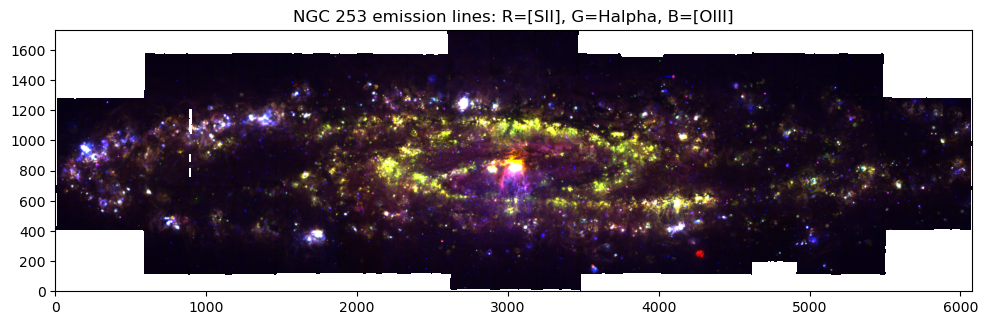

In [11]:
rgb = np.dstack([
    percentile_norm(sii),
    percentile_norm(ha),
    percentile_norm(oiii)])

plt.figure(figsize=(10, 5))
plt.imshow(rgb, origin="lower")
plt.title("NGC 253 emission lines: R=[SII], G=Halpha, B=[OIII]")
plt.tight_layout()
plt.show()

## Build the global-noise detection image

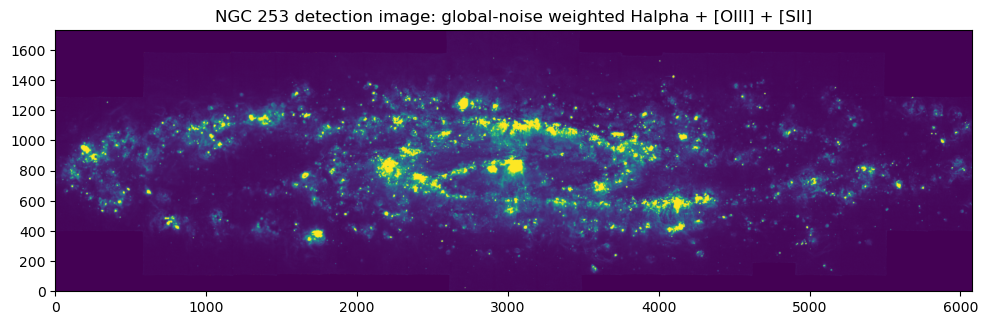

In [12]:
detection = det_map(
    ha, ha_err,
    oiii, oiii_err,
    sii, sii_err,
    snr_min=DETECTION_SNR_MIN,
    noise_method=NOISE_METHOD,)

plt.figure(figsize=(10, 5))
plt.imshow(percentile_norm(detection), origin="lower")
plt.title("NGC 253 detection image: global-noise weighted Halpha + [OIII] + [SII]")
plt.tight_layout()
plt.show()

## Test the astrodendro marker parameters

The old `deblend_sources` parameters are no longer needed. The following runs test only the parameters that determine whether a peak is reliable enough to become a marker.

In [13]:
segmentation_runs = {
    "run_1": {"min_value": 20.0, "min_delta": 15.0, "min_npix": 100},
    "run_2": {"min_value": 20.0, "min_delta": 20.0, "min_npix": 150},
    "run_3": {"min_value": 25.0, "min_delta": 20.0, "min_npix": 150},
    "run_4": {"min_value": 25.0, "min_delta": 25.0, "min_npix": 250},}

In [36]:
segmentation_results = {}

for run_name, parameters in segmentation_runs.items():
    print(f"Running {run_name}: {parameters}")
    result = run_segmentation(detection, **parameters)
    result["params"] = parameters
    segmentation_results[run_name] = result

    print(
        f"  markers={result['n_markers']}, "
        f"watershed={result['n_watershed_regions']}, "
        f"final={result['n_final_regions']}")

Running run_1: {'min_value': 20.0, 'min_delta': 15.0, 'min_npix': 100}
  markers=2013, watershed=2013, final=2013
Running run_2: {'min_value': 20.0, 'min_delta': 20.0, 'min_npix': 150}
  markers=1438, watershed=1438, final=1438
Running run_3: {'min_value': 25.0, 'min_delta': 20.0, 'min_npix': 150}
  markers=1361, watershed=1361, final=1361
Running run_4: {'min_value': 25.0, 'min_delta': 25.0, 'min_npix': 250}
  markers=935, watershed=935, final=935


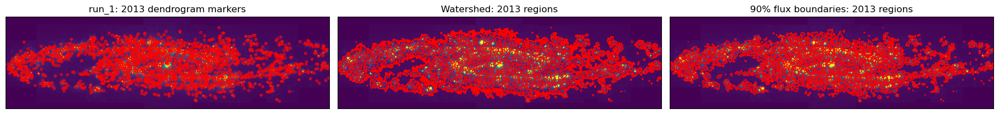

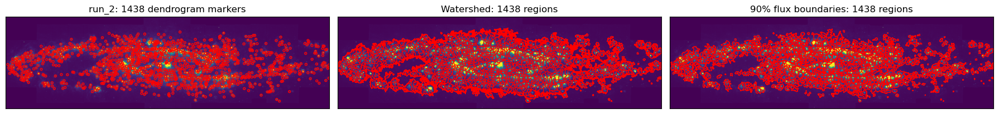

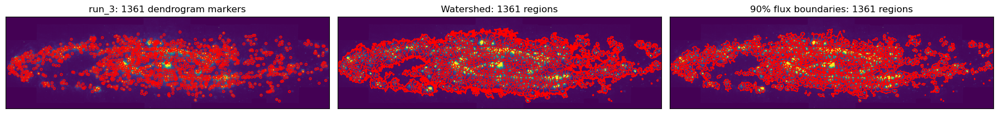

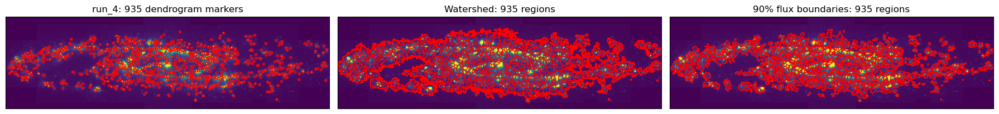

In [37]:
for run_name, result in segmentation_results.items():
    plot_segmentation_result(run_name, result, detection)

In [38]:
segmentation_summary = pd.DataFrame([
    {
        "run_name": run_name,
        **result["params"],
        "n_markers": result["n_markers"],
        "n_watershed_regions": result["n_watershed_regions"],
        "n_final_regions": result["n_final_regions"],
    }
    for run_name, result in segmentation_results.items()
])

segmentation_summary

,run_name,min_value,min_delta,min_npix,n_markers,n_watershed_regions,n_final_regions
0,run_1,20.0,15.0,100,2013,2013,2013
1,run_2,20.0,20.0,150,1438,1438,1438
2,run_3,25.0,20.0,150,1361,1361,1361
3,run_4,25.0,25.0,250,935,935,935


## Select one segmentation run

In [39]:
# Change this after visually comparing the four runs.
selected_run = "run_3"
selected_result = segmentation_results[selected_run]

markers = selected_result["markers"]
support_mask = selected_result["support_mask"]
watershed_labels = selected_result["watershed_labels"]
labels_data = selected_result["labels_data"]
selected_segmentation_params = selected_result["params"]

print("Selected run:", selected_run)
print("Selected parameters:", selected_segmentation_params)
print("Final number of regions:", count_regions(labels_data))

Selected run: run_3
Selected parameters: {'min_value': 25.0, 'min_delta': 20.0, 'min_npix': 150}
Final number of regions: 1361


## Build the region table — no automatic rejection

In [40]:
region_catalog = make_region_catalog(
    labels_data=labels_data,
    detection=detection,
    ha=ha,
    ha_err=ha_err,
    oiii=oiii,
    oiii_err=oiii_err,
    sii=sii,
    sii_err=sii_err,
    wcs=wcs,
    pix_scale=PIX_SCALE,
)

region_catalog[[
    "npix", "r_eq_arcsec", "elongation",
    "det_peak", "det_median", "sn_ha", "sn_oiii", "sn_sii",
]].describe()

,npix,r_eq_arcsec,elongation,det_peak,det_median,sn_ha,sn_oiii,sn_sii
count,1361.000000,1361.000000,1360.000000,1.361000e+03,1.361000e+03,1361.000000,1361.000000,1361.000000
mean,2145.663483,4.880369,1.622044,3.664310e+03,3.228134e+03,1497.180657,235.234743,666.657326
std,1728.095525,1.871900,0.437283,1.168984e+05,1.168882e+05,1073.196525,291.844364,452.946098
min,1.000000,0.112838,1.017865,4.527922e+01,1.432245e+01,18.639208,0.798920,10.262414
25%,961.000000,3.497975,1.301431,9.976038e+01,2.842553e+01,837.434042,117.441242,392.574066
50%,1634.000000,4.561221,1.518669,1.831360e+02,4.201935e+01,1201.606606,171.422017,560.008727
75%,2859.000000,6.033400,1.812926,3.937024e+02,6.455008e+01,1778.893608,251.814198,802.815085
max,16470.000000,14.481110,4.579130,4.312267e+06,4.312267e+06,14139.020839,6081.611108,7055.476709


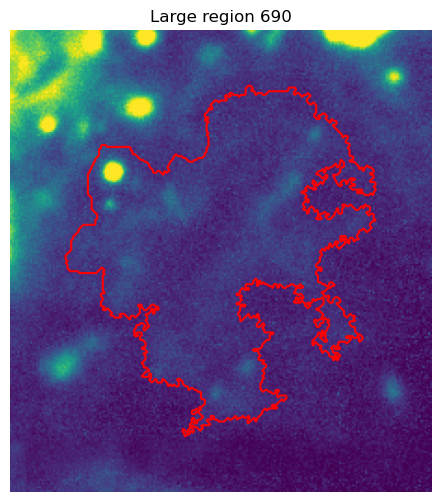

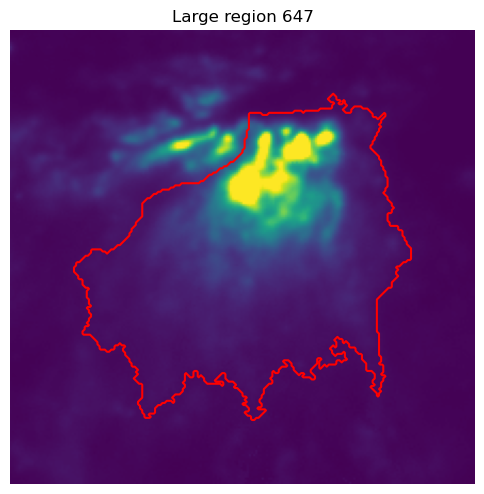

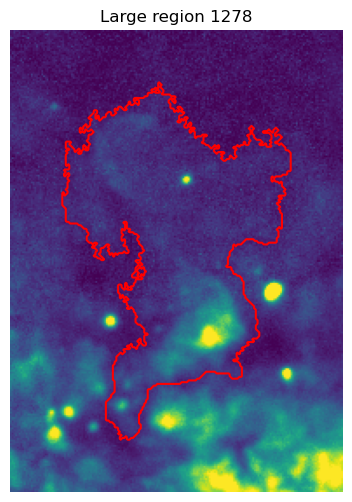

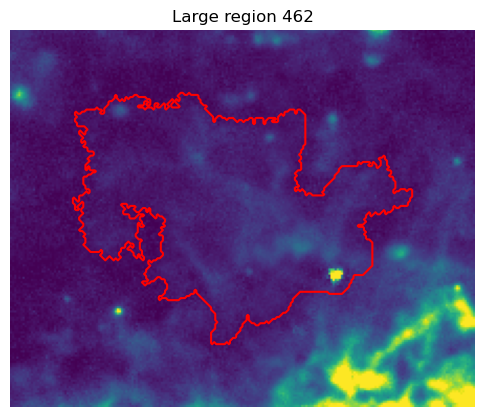

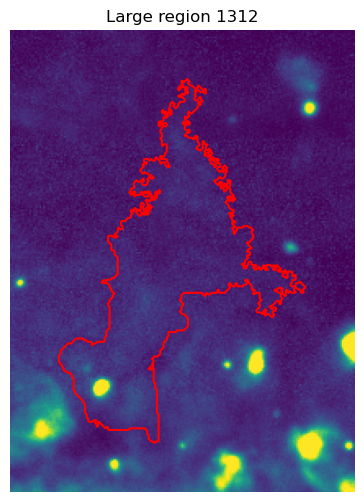

In [41]:
# Optional visual inspection of the largest final masks.
largest_ids = region_catalog.nlargest(5, "npix")["region_id"]

for region_id in largest_ids:
    mask = labels_data == region_id
    y, x = np.where(mask)
    slc = np.s_[
        max(y.min() - 30, 0):min(y.max() + 31, labels_data.shape[0]),
        max(x.min() - 30, 0):min(x.max() + 31, labels_data.shape[1]),
    ]

    plt.figure(figsize=(6, 6))
    plt.imshow(percentile_norm(detection[slc]), origin="lower")
    plt.contour(mask[slc].astype(float), levels=[0.5], colors="red", linewidths=1.5)
    plt.title(f"Large region {region_id}")
    plt.axis("off")
    plt.show()

## Local background subtraction and integrated line fluxes

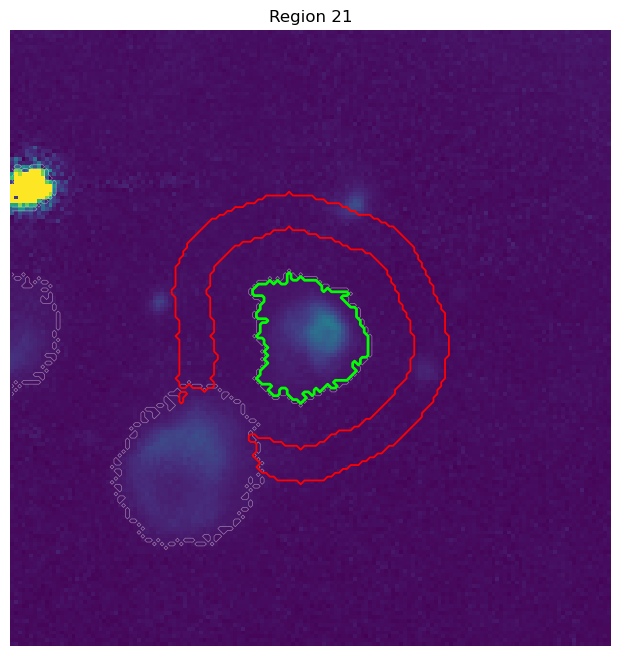

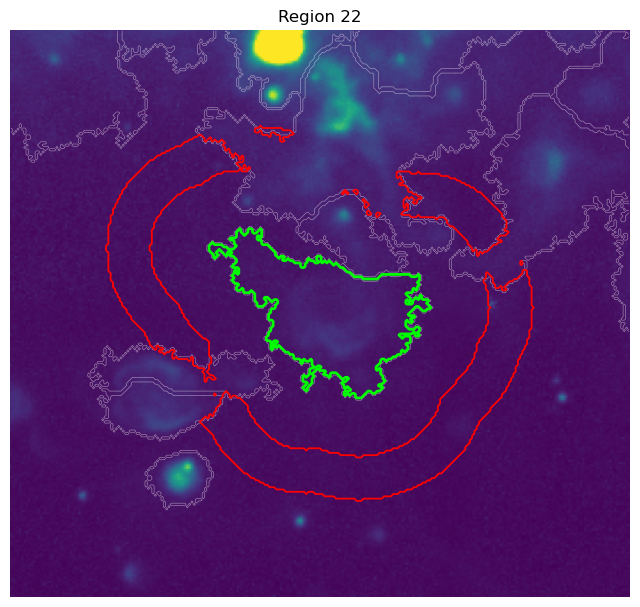

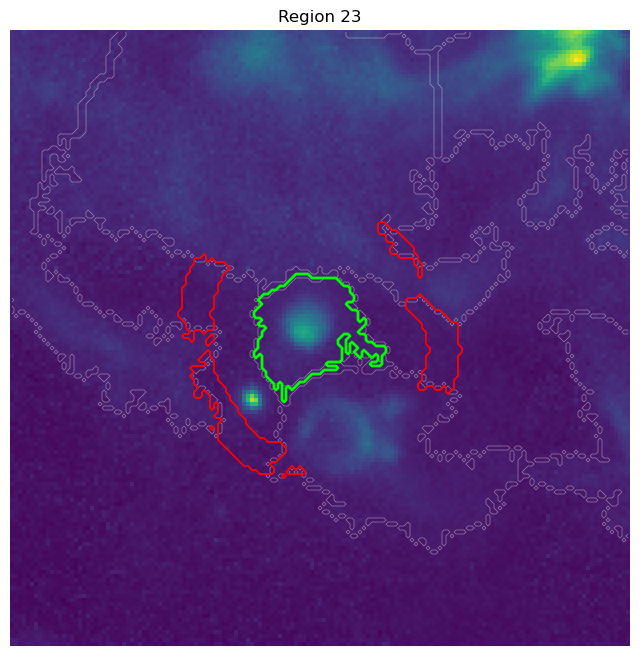

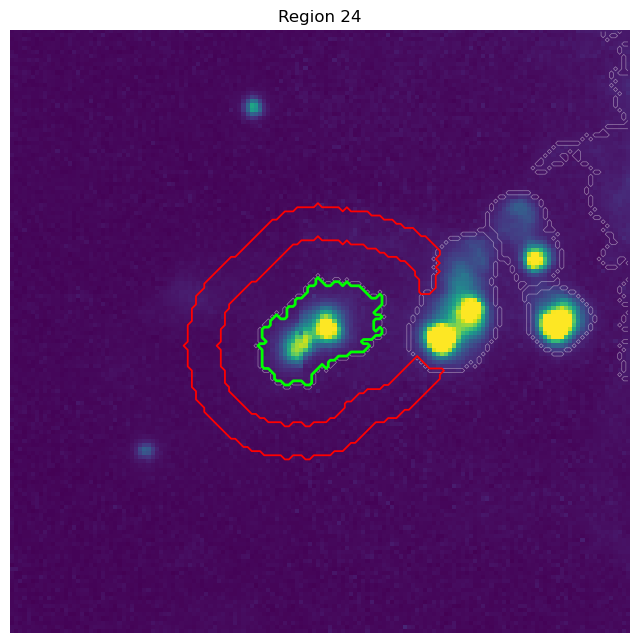

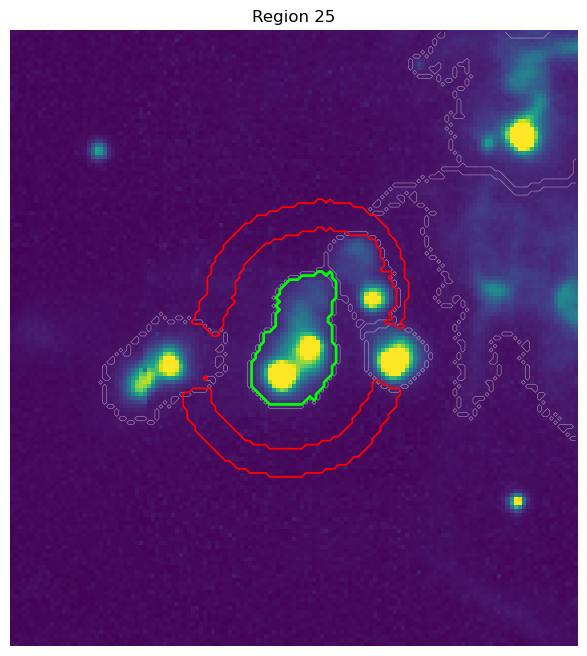

In [42]:
label_slices = ndi.find_objects(labels_data)
region_lookup = region_catalog.set_index("region_id")
region_ids = region_catalog["region_id"].to_numpy()

# Inspect a few ordinary source/annulus definitions.
for region_id in region_ids[20:25]:
    source_crop, annulus_crop, slc = make_local_annulus(
        labels_data,
        region_id,
        region_lookup,
        label_slices,
        inner_factor=ANNULUS_INNER_FACTOR,
        outer_factor=ANNULUS_OUTER_FACTOR,
    )

    show_source_annulus(
        percentile_norm(detection),
        source_crop,
        annulus_crop,
        slc,
        labels_data=labels_data,
        title=f"Region {region_id}",
        pad=40,
    )

In [21]:
line_maps = {
    "ha": ha,
    "hb": hb,
    "oiii": oiii,
    "nii": nii,
    "sii": sii,
    "oi": oi,
}

line_err_maps = {
    "ha": ha_err,
    "hb": hb_err,
    "oiii": oiii_err,
    "nii": nii_err,
    "sii": sii_err,
    "oi": oi_err,
}

In [22]:
rows = []

for region_id in tqdm(region_ids):
    row = extract_region_fluxes(
        labels_data,
        region_id,
        region_lookup,
        label_slices,
        line_maps,
        line_err_maps,
        inner_factor=ANNULUS_INNER_FACTOR,
        outer_factor=ANNULUS_OUTER_FACTOR,
        min_annulus_pix=MIN_ANNULUS_PIX,
    )

    if row is not None:
        rows.append(row)

flux_catalog = pd.DataFrame(rows)
catalogue = region_catalog.merge(flux_catalog, on="region_id", how="left")

print("Segmented regions:", len(region_catalog))
print("Measured regions:", len(flux_catalog))
print("Merged catalogue:", len(catalogue))

  0%|          | 0/1361 [00:00<?, ?it/s]

Segmented regions: 1361
Measured regions: 1361
Merged catalogue: 1361


In [23]:
# These are information flags only. No region is removed.
catalogue["flag_high_ha_bg"] = catalogue["ha_bg_fraction"] > 0.9
catalogue["flag_high_oiii_bg"] = catalogue["oiii_bg_fraction"] > 0.9
catalogue["flag_high_sii_bg"] = catalogue["sii_bg_fraction"] > 0.9
catalogue["flag_high_oi_bg"] = catalogue["oi_bg_fraction"] > 0.9

catalogue["flag_background_warning"] = (
    catalogue["flag_bad_annulus"]
    | catalogue["flag_high_ha_bg"]
    | catalogue["flag_high_oiii_bg"]
    | catalogue["flag_high_sii_bg"]
    | catalogue["flag_high_oi_bg"]
)

catalogue[["flag_bad_annulus", "flag_background_warning"]].sum()

flag_bad_annulus            10
flag_background_warning    143
dtype: int64

## Corrected line ratios and Halpha contrast

In [24]:
for suffix in ("raw", "corr"):
    catalogue[f"log_sii_ha_{suffix}"] = safe_log10_ratio(
        catalogue[f"sii_{suffix}_flux"], catalogue[f"ha_{suffix}_flux"]
    )
    catalogue[f"log_oiii_ha_{suffix}"] = safe_log10_ratio(
        catalogue[f"oiii_{suffix}_flux"], catalogue[f"ha_{suffix}_flux"]
    )
    catalogue[f"log_sii_oiii_{suffix}"] = safe_log10_ratio(
        catalogue[f"sii_{suffix}_flux"], catalogue[f"oiii_{suffix}_flux"]
    )
    catalogue[f"log_oi_ha_{suffix}"] = safe_log10_ratio(
        catalogue[f"oi_{suffix}_flux"], catalogue[f"ha_{suffix}_flux"]
    )
    catalogue[f"log_nii_ha_{suffix}"] = safe_log10_ratio(
        catalogue[f"nii_{suffix}_flux"], catalogue[f"ha_{suffix}_flux"]
    )
    catalogue[f"log_oiii_hb_{suffix}"] = safe_log10_ratio(
        catalogue[f"oiii_{suffix}_flux"], catalogue[f"hb_{suffix}_flux"]
    )

catalogue["sii_ha_corr"] = 10 ** catalogue["log_sii_ha_corr"]
catalogue["oiii_ha_corr"] = 10 ** catalogue["log_oiii_ha_corr"]
catalogue["oi_ha_corr"] = 10 ** catalogue["log_oi_ha_corr"]
catalogue["nii_ha_corr"] = 10 ** catalogue["log_nii_ha_corr"]
catalogue["oiii_hb_corr"] = 10 ** catalogue["log_oiii_hb_corr"]

# Mean Halpha excess above the local background, in units of the annulus pixel scatter.
ha_mean_excess = catalogue["ha_corr_flux"] / catalogue["n_src_pix"]
catalogue["ha_contrast"] = np.divide(
    ha_mean_excess,
    catalogue["ha_bg_sigma"],
    out=np.full(len(catalogue), np.nan),
    where=catalogue["ha_bg_sigma"].to_numpy() > 0,
)

catalogue["ha_corr_sb"] = catalogue["ha_corr_flux"] / catalogue["area_arcsec2"]

catalogue[["ha_contrast", "ha_corr_sb", "sii_ha_corr", "oiii_ha_corr"]].describe()

,ha_contrast,ha_corr_sb,sii_ha_corr,oiii_ha_corr
count,1.358000e+03,1.358000e+03,1325.000000,1.320000e+03
mean,1.625797e+03,2.522666e+06,0.557343,1.316886e+03
std,5.965378e+04,9.205194e+07,6.193252,4.783437e+04
min,-8.119274e-01,-6.249044e+03,0.000004,1.122860e-06
25%,2.318608e+00,7.098274e+03,0.230668,5.380506e-02
50%,4.583927e+00,1.388471e+04,0.297608,1.097890e-01
75%,8.539669e+00,2.747520e+04,0.382633,1.875140e-01
max,2.198311e+06,3.392235e+09,223.391506,1.737909e+06


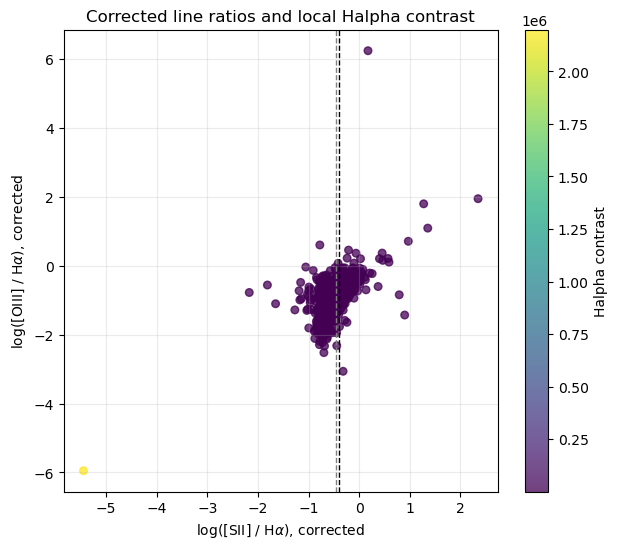

In [25]:
plt.figure(figsize=(7, 6))
valid = np.isfinite(catalogue["log_sii_ha_corr"]) & np.isfinite(catalogue["log_oiii_ha_corr"])

plt.scatter(
    catalogue.loc[valid, "log_sii_ha_corr"],
    catalogue.loc[valid, "log_oiii_ha_corr"],
    c=catalogue.loc[valid, "ha_contrast"],
    s=30,
    alpha=0.75,
)
plt.colorbar(label="Halpha contrast")
plt.axvline(np.log10(SII_HA_DIG_LIKE), color="gray", linestyle="--", linewidth=1)
plt.axvline(np.log10(SII_HA_SHOCK_LIKE), color="black", linestyle="--", linewidth=1)
plt.xlabel(r"log([SII] / H$\alpha$), corrected")
plt.ylabel(r"log([OIII] / H$\alpha$), corrected")
plt.title("Corrected line ratios and local Halpha contrast")
plt.grid(alpha=0.25)
plt.show()

## First-pass H II and SNR/shock classification

A missing BPT measurement is kept as a separate state. It is not treated as evidence that a source lies in the H II part of the BPT diagram.

In [26]:
# Reliability of the corrected line measurements.
for line in ("ha", "hb", "oiii", "nii", "sii", "oi"):
    catalogue[f"flag_{line}_reliable"] = (
        np.isfinite(catalogue[f"{line}_corr_flux"])
        & np.isfinite(catalogue[f"{line}_corr_sn"])
        & (catalogue[f"{line}_corr_flux"] > 0)
        & (catalogue[f"{line}_corr_sn"] >= LINE_SN_MIN)
    )

catalogue["flag_sii_ha_reliable"] = (
    catalogue["flag_sii_reliable"] & catalogue["flag_ha_reliable"]
)
catalogue["flag_oi_ha_reliable"] = (
    catalogue["flag_oi_reliable"] & catalogue["flag_ha_reliable"]
)
catalogue["flag_bpt_reliable"] = (
    catalogue["flag_ha_reliable"]
    & catalogue["flag_hb_reliable"]
    & catalogue["flag_nii_reliable"]
    & catalogue["flag_oiii_reliable"]
)

catalogue["bpt_tag"] = "unclassified_BPT"
bpt_ok = catalogue["flag_bpt_reliable"]

catalogue.loc[bpt_ok, "bpt_tag"] = [
    classify_bpt(n2, o3hb)
    for n2, o3hb in zip(
        catalogue.loc[bpt_ok, "log_nii_ha_corr"],
        catalogue.loc[bpt_ok, "log_oiii_hb_corr"],
    )
]

catalogue["flag_bpt_hii"] = catalogue["bpt_tag"].isin([
    "HII_BPT_clean", "HII_BPT_possible"
])
catalogue["flag_bpt_non_hii"] = catalogue["bpt_tag"] == "non_HII_BPT"
catalogue["flag_bpt_unavailable"] = ~catalogue["flag_bpt_reliable"]

catalogue["flag_high_ha_contrast"] = catalogue["ha_contrast"] >= HA_CONTRAST_MIN
catalogue["flag_low_ha_contrast"] = (
    np.isfinite(catalogue["ha_contrast"])
    & (catalogue["ha_contrast"] < HA_CONTRAST_MIN)
)

catalogue["flag_low_sii"] = (
    catalogue["flag_sii_ha_reliable"]
    & (catalogue["sii_ha_corr"] < SII_HA_DIG_LIKE)
)
catalogue["flag_moderate_sii"] = (
    catalogue["flag_sii_ha_reliable"]
    & (catalogue["sii_ha_corr"] >= SII_HA_DIG_LIKE)
    & (catalogue["sii_ha_corr"] < SII_HA_SHOCK_LIKE)
)
catalogue["flag_high_sii"] = (
    catalogue["flag_sii_ha_reliable"]
    & (catalogue["sii_ha_corr"] >= SII_HA_SHOCK_LIKE)
)
catalogue["flag_high_oi"] = (
    catalogue["flag_oi_ha_reliable"]
    & (catalogue["oi_ha_corr"] >= OI_HA_SHOCK_LIKE)
)

catalogue["flag_shock_spectrum"] = (
    catalogue["flag_high_sii"]
    | catalogue["flag_high_oi"]
    | catalogue["flag_bpt_non_hii"]
)

In [27]:
catalogue["first_pass_tag"] = "ambiguous"

# H II-like line ratios with a reliable BPT classification.
catalogue.loc[
    catalogue["flag_high_ha_contrast"]
    & catalogue["flag_low_sii"]
    & catalogue["flag_bpt_hii"],
    "first_pass_tag",
] = "hii_candidate_bpt"

# H II-like line ratios when the BPT lines are unavailable.
# The separate label keeps the missing BPT information explicit.
catalogue.loc[
    catalogue["flag_high_ha_contrast"]
    & catalogue["flag_low_sii"]
    & catalogue["flag_bpt_unavailable"],
    "first_pass_tag",
] = "hii_candidate_no_bpt"

catalogue.loc[
    catalogue["flag_high_ha_contrast"]
    & catalogue["flag_moderate_sii"]
    & ~catalogue["flag_bpt_non_hii"],
    "first_pass_tag",
] = "transition_sii_candidate"

# Low-contrast low-ionisation emission is more likely diffuse/filamentary.
catalogue.loc[
    catalogue["flag_low_ha_contrast"]
    & (catalogue["flag_moderate_sii"] | catalogue["flag_shock_spectrum"]),
    "first_pass_tag",
] = "dig_or_filament_candidate"

# High-contrast shock-like emission remains an SNR/shock candidate, not a secure SNR.
catalogue.loc[
    catalogue["flag_high_ha_contrast"]
    & catalogue["flag_shock_spectrum"],
    "first_pass_tag",
] = "snr_or_shock_candidate"

catalogue["first_pass_tag"].value_counts()

first_pass_tag
hii_candidate_bpt            517
dig_or_filament_candidate    283
snr_or_shock_candidate       278
ambiguous                    176
transition_sii_candidate      85
hii_candidate_no_bpt          22
Name: count, dtype: int64

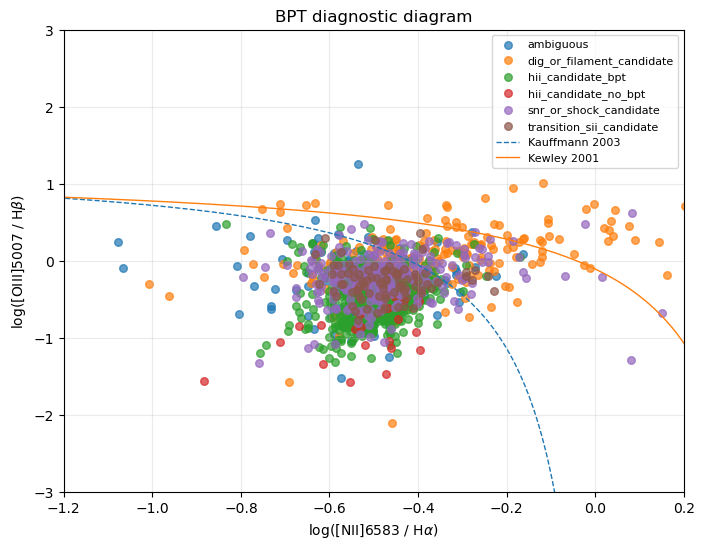

In [28]:
# BPT diagram
plot_catalogue = catalogue[
    np.isfinite(catalogue["log_nii_ha_corr"])
    & np.isfinite(catalogue["log_oiii_hb_corr"])
].copy()

x = np.linspace(-2.0, 0.45, 400)
kauffmann_x = x[x < 0.05]
kauffmann_y = 0.61 / (kauffmann_x - 0.05) + 1.30
kewley_x = x[x < 0.47]
kewley_y = 0.61 / (kewley_x - 0.47) + 1.19

plt.figure(figsize=(8, 6))
for tag, group in plot_catalogue.groupby("first_pass_tag"):
    plt.scatter(
        group["log_nii_ha_corr"], group["log_oiii_hb_corr"],
        s=30, alpha=0.7, label=tag,
    )

plt.plot(kauffmann_x, kauffmann_y, "--", linewidth=1, label="Kauffmann 2003")
plt.plot(kewley_x, kewley_y, "-", linewidth=1, label="Kewley 2001")
plt.xlim(-1.2, 0.2)
plt.ylim(-3, 3)
plt.xlabel(r"log([NII]6583 / H$\alpha$)")
plt.ylabel(r"log([OIII]5007 / H$\beta$)")
plt.title("BPT diagnostic diagram")
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.show()

Region 27 | hii_candidate_bpt | [SII]/Halpha=0.35 | Halpha contrast=3.35 | r=5.07 arcsec


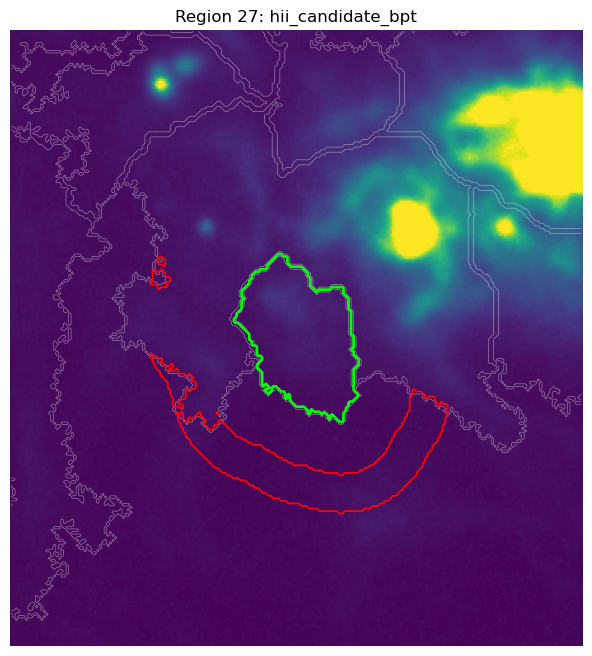

Region 33 | hii_candidate_bpt | [SII]/Halpha=0.27 | Halpha contrast=18.33 | r=12.15 arcsec


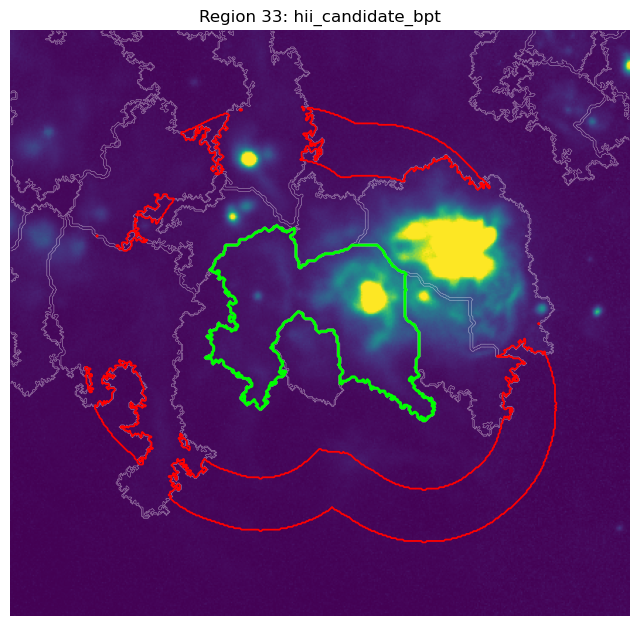

Region 36 | hii_candidate_bpt | [SII]/Halpha=0.31 | Halpha contrast=15.64 | r=7.34 arcsec


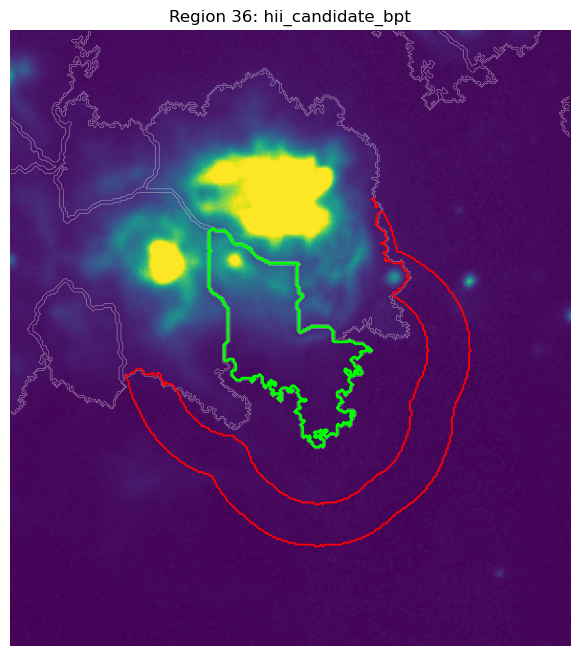

Region 41 | hii_candidate_bpt | [SII]/Halpha=0.24 | Halpha contrast=71.13 | r=11.56 arcsec


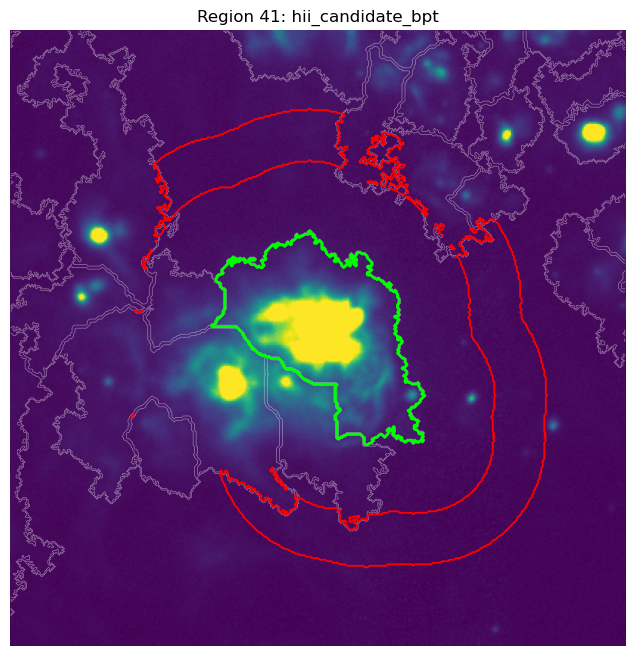

Region 49 | hii_candidate_bpt | [SII]/Halpha=0.35 | Halpha contrast=11.35 | r=4.79 arcsec


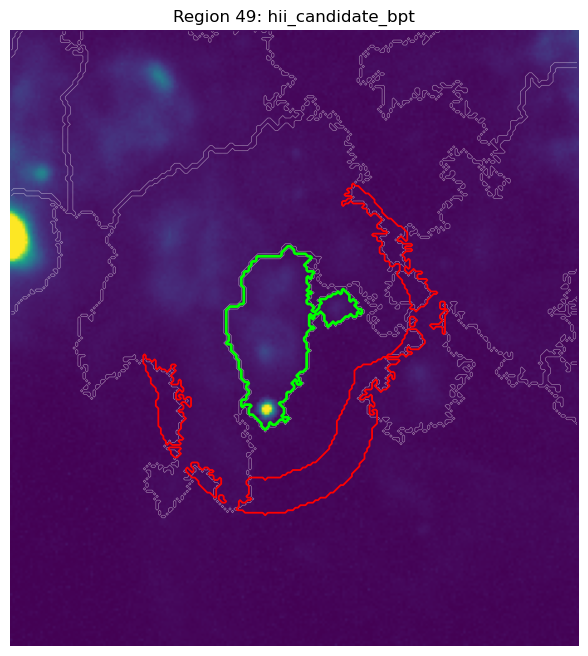

Region 1 | snr_or_shock_candidate | [SII]/Halpha=0.33 | Halpha contrast=20.25 | r=7.31 arcsec


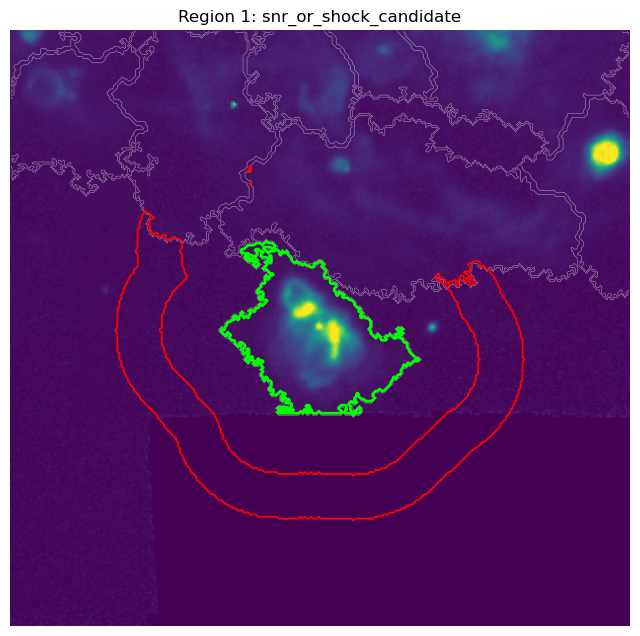

Region 2 | snr_or_shock_candidate | [SII]/Halpha=0.24 | Halpha contrast=13.24 | r=2.88 arcsec


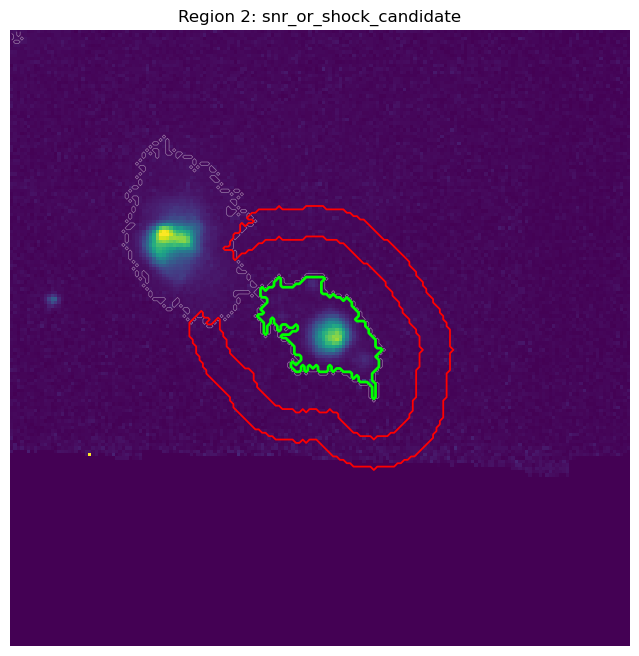

Region 3 | snr_or_shock_candidate | [SII]/Halpha=0.22 | Halpha contrast=14.69 | r=3.99 arcsec


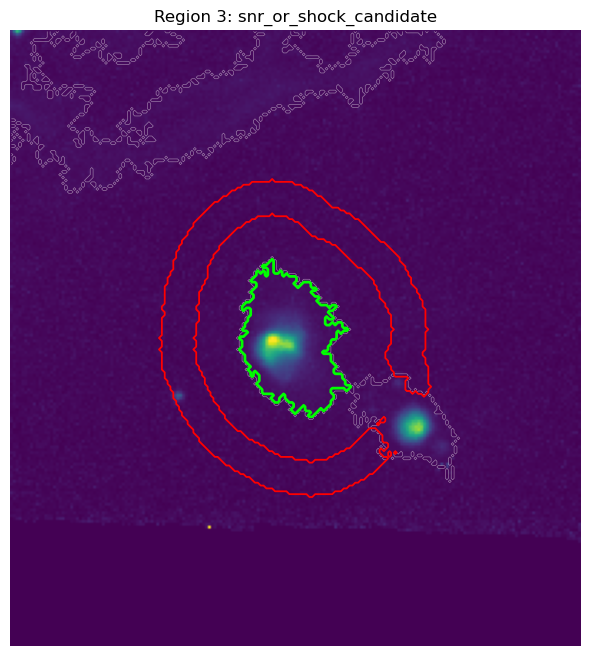

Region 4 | snr_or_shock_candidate | [SII]/Halpha=0.41 | Halpha contrast=3.47 | r=8.52 arcsec


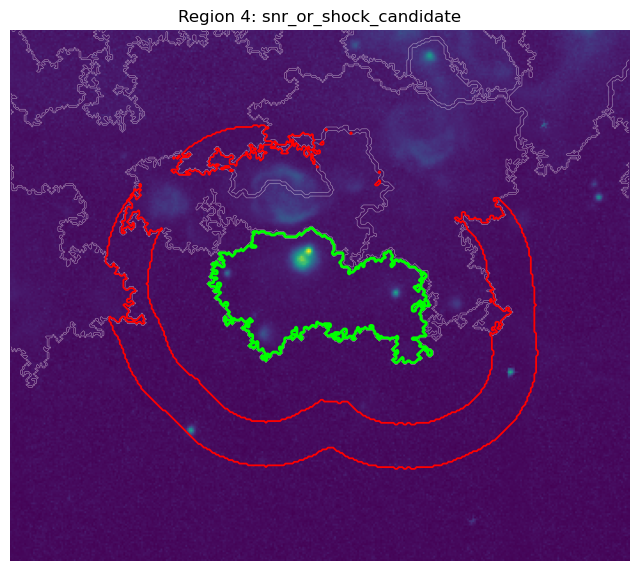

Region 5 | snr_or_shock_candidate | [SII]/Halpha=0.29 | Halpha contrast=3.88 | r=9.77 arcsec


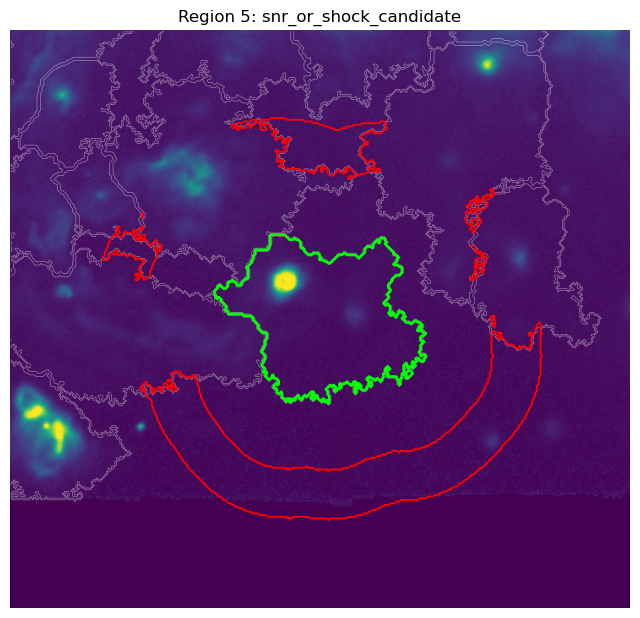

Region 8 | dig_or_filament_candidate | [SII]/Halpha=0.44 | Halpha contrast=2.70 | r=15.51 arcsec


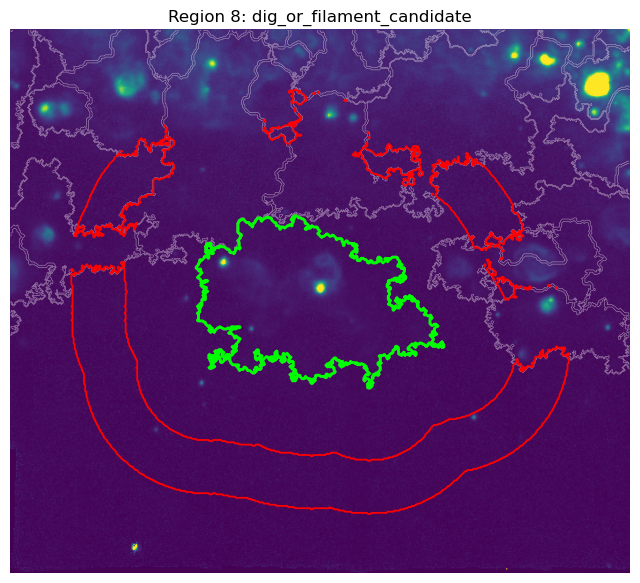

Region 10 | dig_or_filament_candidate | [SII]/Halpha=6.19 | Halpha contrast=2.70 | r=6.68 arcsec


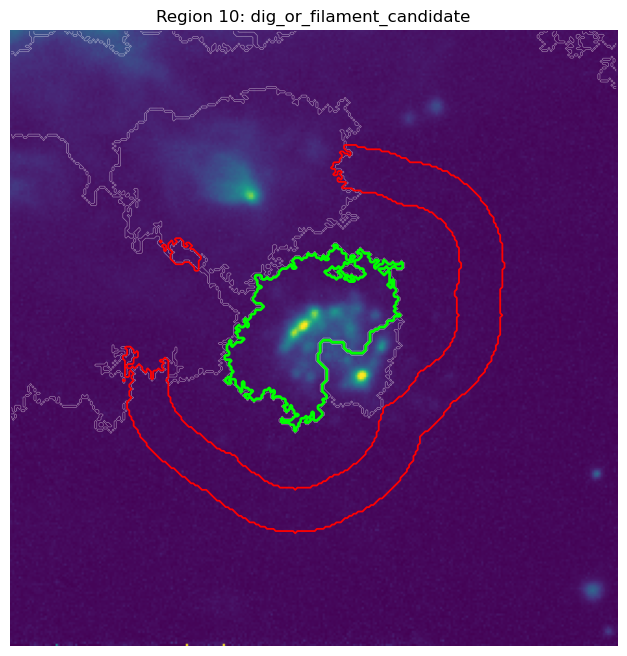

Region 11 | dig_or_filament_candidate | [SII]/Halpha=0.50 | Halpha contrast=0.50 | r=7.56 arcsec


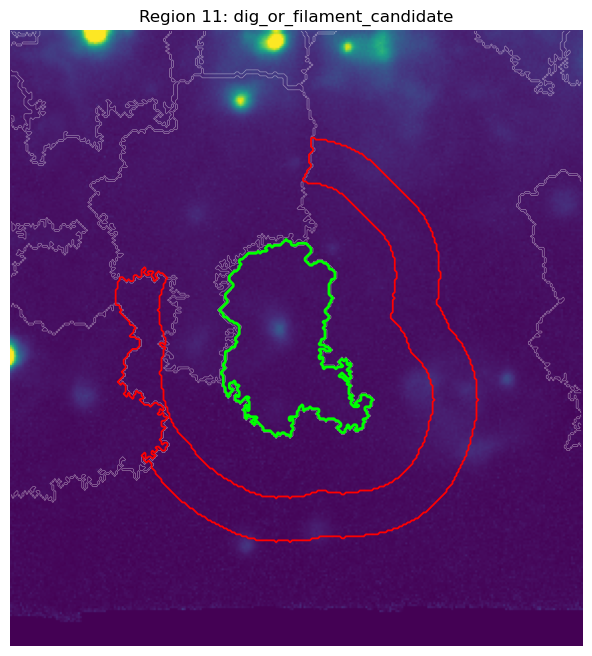

Region 13 | dig_or_filament_candidate | [SII]/Halpha=0.66 | Halpha contrast=1.82 | r=5.69 arcsec


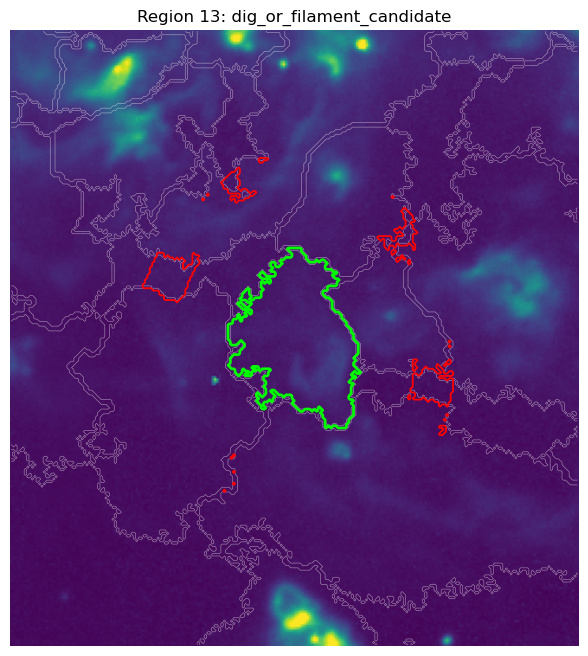

Region 14 | dig_or_filament_candidate | [SII]/Halpha=0.39 | Halpha contrast=2.17 | r=8.09 arcsec


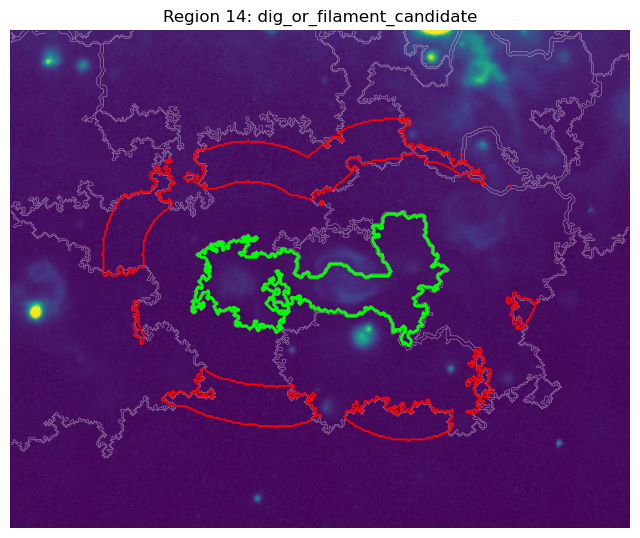

In [29]:
# Inspect examples without duplicating plotting loops.
inspect_regions(catalogue, "hii_candidate_bpt", percentile_norm(ha), n=5)
inspect_regions(catalogue, "snr_or_shock_candidate", percentile_norm(detection), n=5)
inspect_regions(catalogue, "dig_or_filament_candidate", percentile_norm(detection), n=5)

## Save catalogue, segmentation maps, and parameters

In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

catalogue.to_pickle(OUTPUT_DIR / "first_pass_catalog.pkl")
catalogue.to_csv(OUTPUT_DIR / "first_pass_catalog.csv", index=False)
region_catalog.to_pickle(OUTPUT_DIR / "region_catalog.pkl")
flux_catalog.to_pickle(OUTPUT_DIR / "flux_catalog.pkl")
segmentation_summary.to_csv(OUTPUT_DIR / "segmentation_summary.csv", index=False)

seg_header = header.copy()
seg_header["BUNIT"] = "label"
seg_header["COMMENT"] = "0 = background; positive integers = region IDs"

fits.writeto(
    OUTPUT_DIR / "labels_data.fits",
    labels_data.astype(np.int32),
    seg_header,
    overwrite=True,
)
fits.writeto(
    OUTPUT_DIR / "watershed_labels.fits",
    watershed_labels.astype(np.int32),
    seg_header,
    overwrite=True,
)
fits.writeto(
    OUTPUT_DIR / "markers.fits",
    markers.astype(np.int32),
    seg_header,
    overwrite=True,
)
fits.writeto(
    OUTPUT_DIR / "support_mask.fits",
    support_mask.astype(np.uint8),
    header,
    overwrite=True,
)
fits.writeto(
    OUTPUT_DIR / "detection.fits",
    detection.astype(np.float32),
    header,
    overwrite=True,
)

metadata = {
    "selected_segmentation_run": selected_run,
    "selected_segmentation_params": selected_segmentation_params,
    "tested_segmentation_runs": segmentation_summary.to_dict(orient="records"),
    "support_threshold": SUPPORT_THRESHOLD,
    "watershed_smooth_sigma": WATERSHED_SMOOTH_SIGMA,
    "boundary_flux_fraction": BOUNDARY_FLUX_FRACTION,
    "boundary_annulus_inner_pix": BOUNDARY_ANNULUS_INNER_PIX,
    "boundary_annulus_outer_pix": BOUNDARY_ANNULUS_OUTER_PIX,
    "annulus_inner_factor": ANNULUS_INNER_FACTOR,
    "annulus_outer_factor": ANNULUS_OUTER_FACTOR,
    "min_annulus_pix": MIN_ANNULUS_PIX,
    "pix_scale_arcsec": PIX_SCALE,
    "psf_fwhm_arcsec": PSF_FWHM_ARCSEC,
    "line_sn_min": LINE_SN_MIN,
    "ha_contrast_min": HA_CONTRAST_MIN,
    "sii_ha_dig_like": SII_HA_DIG_LIKE,
    "sii_ha_shock_like": SII_HA_SHOCK_LIKE,
    "oi_ha_shock_like": OI_HA_SHOCK_LIKE,
    "final_n_regions": int(count_regions(labels_data)),
    "input_fits_path": str(DATA_FITS),
    "planetary_nebula_branch_used": False,
}

with open(OUTPUT_DIR / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Saved results to", OUTPUT_DIR.resolve())

In [ ]:
hdul.close()